In [1]:
from google.colab import files
uploaded = files.upload()   # pilih fishpond_dataset_multiclass_2153.csv

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("fishpond_dataset_multiclass_2153.csv")

# Urutan kelas mengikuti tingkat keparahan
KELAS = ["Normal", "Caution", "Warning", "Severe"]
LABEL2ID = {k: i for i, k in enumerate(KELAS)}   # Normal=0 ... Severe=3

df = df[["temp_C", "turbidity_NTU", "class"]].dropna()
df["label"] = df["class"].map(LABEL2ID)

print("Jumlah data:", len(df))
print(df["class"].value_counts().reindex(KELAS))
print(df.groupby("class")[["temp_C", "turbidity_NTU"]].agg(["min", "median", "max"]).round(2))

Jumlah data: 2153
class
Normal     638
Caution    670
Warning    478
Severe     367
Name: count, dtype: int64
        temp_C               turbidity_NTU                
           min median    max           min  median     max
class                                                     
Caution  23.01  24.97  32.00         25.01   37.61   49.98
Normal   25.00  27.48  29.96          1.02   13.14   24.96
Severe   15.00  34.08  37.99        151.26  376.28  598.68
Warning  20.01  32.08  34.00         50.01  102.42  149.97


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

FITUR = {
    "suhu":      ["temp_C"],
    "kekeruhan": ["turbidity_NTU"],
    "overall":   ["temp_C", "turbidity_NTU"],
}

# Split sekali supaya ketiga model diuji pada data uji yang sama
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["label"], random_state=42
)

models, hasil = {}, []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nama, kolom in FITUR.items():
    model = RandomForestClassifier(
        n_estimators=200, max_depth=None, random_state=42, n_jobs=-1
    )
    model.fit(train_df[kolom], train_df["label"])
    pred = model.predict(test_df[kolom])

    acc = accuracy_score(test_df["label"], pred)
    f1 = f1_score(test_df["label"], pred, average="macro")
    cv_acc = cross_val_score(model, df[kolom], df["label"], cv=cv, scoring="accuracy")

    hasil.append({
        "Model": nama, "Fitur": ", ".join(kolom),
        "Akurasi uji": round(acc * 100, 2),
        "F1 macro": round(f1 * 100, 2),
        "CV 5-fold (mean ± std)": f"{cv_acc.mean()*100:.2f} ± {cv_acc.std()*100:.2f}",
    })
    models[nama] = model

    print(f"\n===== Model {nama.upper()} =====")
    print(classification_report(test_df["label"], pred, target_names=KELAS, digits=4))

print(pd.DataFrame(hasil).to_string(index=False))


===== Model SUHU =====
              precision    recall  f1-score   support

      Normal     1.0000    1.0000    1.0000       128
     Caution     0.9781    1.0000    0.9889       134
     Warning     1.0000    0.9583    0.9787        96
      Severe     0.9865    1.0000    0.9932        73

    accuracy                         0.9907       431
   macro avg     0.9911    0.9896    0.9902       431
weighted avg     0.9909    0.9907    0.9907       431


===== Model KEKERUHAN =====
              precision    recall  f1-score   support

      Normal     1.0000    1.0000    1.0000       128
     Caution     0.9926    1.0000    0.9963       134
     Warning     1.0000    0.9896    0.9948        96
      Severe     1.0000    1.0000    1.0000        73

    accuracy                         0.9977       431
   macro avg     0.9981    0.9974    0.9978       431
weighted avg     0.9977    0.9977    0.9977       431


===== Model OVERALL =====
              precision    recall  f1-score   supp

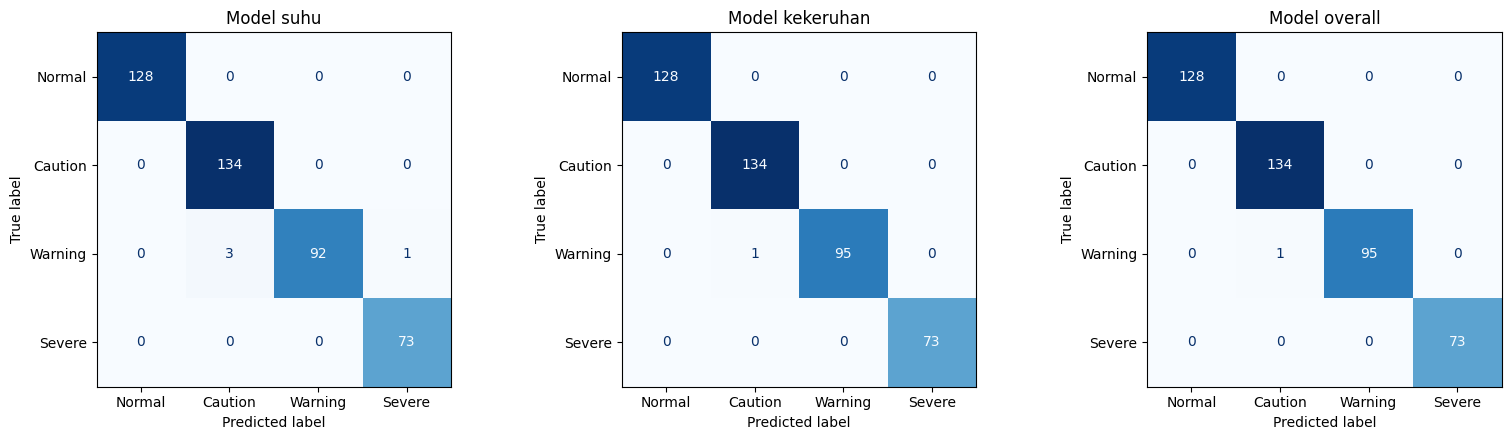

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nama, kolom) in zip(axes, FITUR.items()):
    pred = models[nama].predict(test_df[kolom])
    ConfusionMatrixDisplay(
        confusion_matrix(test_df["label"], pred), display_labels=KELAS
    ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Model {nama}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

In [5]:
import joblib, sklearn

# Suhu acuan = median suhu kelas Normal (penentu arah pemanas/kipas)
SUHU_ACUAN = float(df.loc[df["class"] == "Normal", "temp_C"].median())
print("Suhu acuan:", SUHU_ACUAN)

def tentukan_aksi(suhu, ntu, status_lama=None):
    """Logika Tabel 4.1. Mengembalikan kelas tiap model + perintah aktuator."""
    status_lama = status_lama or {"pemanas": 0, "kipas": 0, "pompa": 0}
    x = pd.DataFrame({"temp_C": [suhu], "turbidity_NTU": [ntu]})

    k_suhu = int(models["suhu"].predict(x[["temp_C"]])[0])
    k_keruh = int(models["kekeruhan"].predict(x[["turbidity_NTU"]])[0])
    k_all = int(models["overall"].predict(x)[0])

    aksi = dict(status_lama)
    # Suhu -> pemanas / kipas
    if k_suhu == 0:                       # Normal
        aksi["pemanas"], aksi["kipas"] = 0, 0
    elif k_suhu >= 2:                     # Warning / Severe
        dingin = suhu < SUHU_ACUAN
        aksi["pemanas"], aksi["kipas"] = int(dingin), int(not dingin)
    # Caution: status dipertahankan (hanya notifikasi)

    # Kekeruhan -> pompa
    if k_keruh == 0:
        aksi["pompa"] = 0
    elif k_keruh >= 2:
        aksi["pompa"] = 1

    return {"suhu": KELAS[k_suhu], "kekeruhan": KELAS[k_keruh],
            "overall": KELAS[k_all], "aksi": aksi}

# Contoh skenario
for s, n in [(27.5, 10), (22, 10), (33, 10), (27, 80), (17, 300), (24.5, 30)]:
    print(f"suhu={s:>5} ntu={n:>4} ->", tentukan_aksi(s, n))

# Simpan semua dalam satu file
paket = {
    "model_suhu": models["suhu"],
    "model_kekeruhan": models["kekeruhan"],
    "model_overall": models["overall"],
    "kelas": KELAS,
    "suhu_acuan": SUHU_ACUAN,
    "fitur": FITUR,
    "sklearn_version": sklearn.__version__,
}
joblib.dump(paket, "smart_aquarium_rf.joblib", compress=3)
print("sklearn versi:", sklearn.__version__)

files.download("smart_aquarium_rf.joblib")
files.download("confusion_matrix.png")

Suhu acuan: 27.48
suhu= 27.5 ntu=  10 -> {'suhu': 'Normal', 'kekeruhan': 'Normal', 'overall': 'Normal', 'aksi': {'pemanas': 0, 'kipas': 0, 'pompa': 0}}
suhu=   22 ntu=  10 -> {'suhu': 'Warning', 'kekeruhan': 'Normal', 'overall': 'Normal', 'aksi': {'pemanas': 1, 'kipas': 0, 'pompa': 0}}
suhu=   33 ntu=  10 -> {'suhu': 'Warning', 'kekeruhan': 'Normal', 'overall': 'Normal', 'aksi': {'pemanas': 0, 'kipas': 1, 'pompa': 0}}
suhu=   27 ntu=  80 -> {'suhu': 'Normal', 'kekeruhan': 'Warning', 'overall': 'Warning', 'aksi': {'pemanas': 0, 'kipas': 0, 'pompa': 1}}
suhu=   17 ntu= 300 -> {'suhu': 'Severe', 'kekeruhan': 'Severe', 'overall': 'Severe', 'aksi': {'pemanas': 1, 'kipas': 0, 'pompa': 1}}
suhu= 24.5 ntu=  30 -> {'suhu': 'Caution', 'kekeruhan': 'Caution', 'overall': 'Caution', 'aksi': {'pemanas': 0, 'kipas': 0, 'pompa': 0}}
sklearn versi: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>